<a href="https://colab.research.google.com/github/TharushiSamarawickrama/DeepLearning_Lab/blob/main/Lab_05(IT22343284Q2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 2 - Implementing LSTM for Time-Series Forecasting**


***Read the following descriptions and instructions***

Time-series forecasting is a crucial task in various fields, including finance, economics, and weather prediction. In this question, you'll work with Long Short-Term Memory (LSTM) networks, a type of recurrent neural network (RNN) that is particularly effective at learning from sequences of data. LSTMs are designed to capture long-term dependencies in time-series data, making them well-suited for predicting future values based on historical patterns.

In this task, you will implement an LSTM model to forecast stock prices using historical data. Specifically, you'll use the closing prices of a stock to predict future prices, which is a common real-world application of time-series analysis in financial markets. This exercise will help you understand the principles of sequence modeling and how LSTMs can be applied to complex prediction tasks.

In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

In [6]:
# 1. Load and Preprocess the Data
def load_data(file_path):
    df = pd.read_csv(file_path)
    print(df.head())      # check first few rows
    print(df.shape)
    return df['Close'].values  # we use only the 'Close' column

In [10]:
# 2. Prepare the Dataset for LSTM
def create_dataset(data, time_step=60):
    X, y = [], []
    for i in range(len(data) - time_step):
        X.append(data[i:(i + time_step)])
        y.append(data[i + time_step])
    return np.array(X), np.array(y)

In [7]:
# Load Data
file_path = '/content/GOOG.csv'  # Path to the dataset in Colab or Jupyter home directory
data = load_data(file_path)

         Date        Open        High         Low       Close   Adj Close  \
0  2021-09-27  141.585495  142.500000  140.500000  141.501007  141.501007   
1  2021-09-28  139.088501  139.606506  135.699997  136.184006  136.184006   
2  2021-09-29  137.109695  137.398499  134.250000  134.520996  134.520996   
3  2021-09-30  134.324997  135.589996  133.000000  133.265503  133.265503   
4  2021-10-01  133.554504  137.070999  133.377502  136.462494  136.462494   

     Volume  
0  18844000  
1  42190000  
2  26338000  
3  35294000  
4  28388000  
(251, 7)


In [8]:
# Normalize the Data
scaler = MinMaxScaler(feature_range=(0, 1))
data = scaler.fit_transform(data.reshape(-1, 1)).reshape(-1)

**time_step = 60:** This variable defines the length of the input sequence, meaning we will use the past 60 days of stock prices to predict the next day's closing price. This value is chosen to capture enough historical information to make an accurate prediction. You can change and try

In [11]:

# Create the Dataset
time_step = 60  # past 60 days → predict next day
X, y = create_dataset(data, time_step)

In [12]:
# Reshape for LSTM input [samples, time steps, features]
X = X.reshape(X.shape[0], X.shape[1], 1)

In [13]:
# Split the Data into Training and Testing Sets (80% train, 20% test)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

***Modify the number of units in the LSTM layers and consider adding more layers or changing the dropout rate to see how these adjustments affect the model's performance***

Experiment with 'units'

Experiment with dropout for regularization

Add another LSTM layer



In [14]:
# 3. Define the LSTM Model
UNITS = 50        # 🔸 try 30, 50, 100
DROPOUT = 0.2     # 🔸 try 0.1 → 0.3

model = Sequential([
    LSTM(units=UNITS, return_sequences=True, input_shape=(time_step, 1)),
    Dropout(DROPOUT),
    LSTM(units=UNITS, return_sequences=False),
    Dropout(DROPOUT),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_absolute_error')
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

***Adjust the epochs and batch_size during the training phase to optimize the model’s learning process and its ability to generalize.***

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0782
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 0.0820
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.0775
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 0.0797
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - loss: 0.0834
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - loss: 0.0742
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - loss: 0.0828
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0784
Epoch 9/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 0.0829
Epoch 10/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0810
Epoch 11/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.0802
Epoch 12/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0812
Epoch 13/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 0.0859
Epoch 14/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0822
Epoch 15/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.0794
Epoch 16/50
5/5 ━━━━━━━━━━━━━━━━━

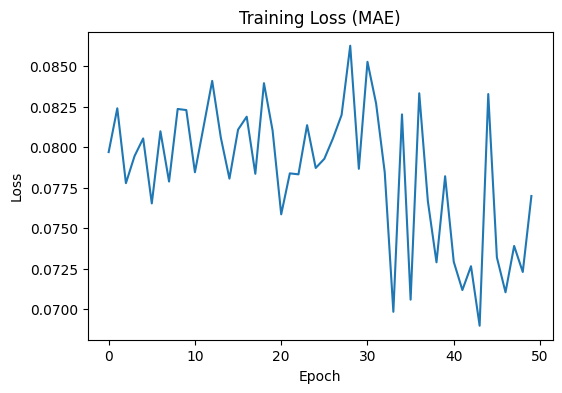

In [17]:
# 4. Train the Model
EPOCHS = 50        # 🔸 try 30, 50, 100
BATCH_SIZE = 32    # 🔸 try 16, 32, 64

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

# plot training loss
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'])
plt.title('Training Loss (MAE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()


In [16]:
# 5. Predict on the Test Data
y_pred = model.predict(X_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 300ms/step


In [18]:
# Inverse transform to get the original scale
y_pred = scaler.inverse_transform(y_pred.reshape(-1,1)).reshape(-1)
y_test_real = scaler.inverse_transform(y_test.reshape(-1,1)).reshape(-1)

***Analyze the plot to evaluate the model performance. Consider modifying the model architecture or training parameters to improve accuracy***

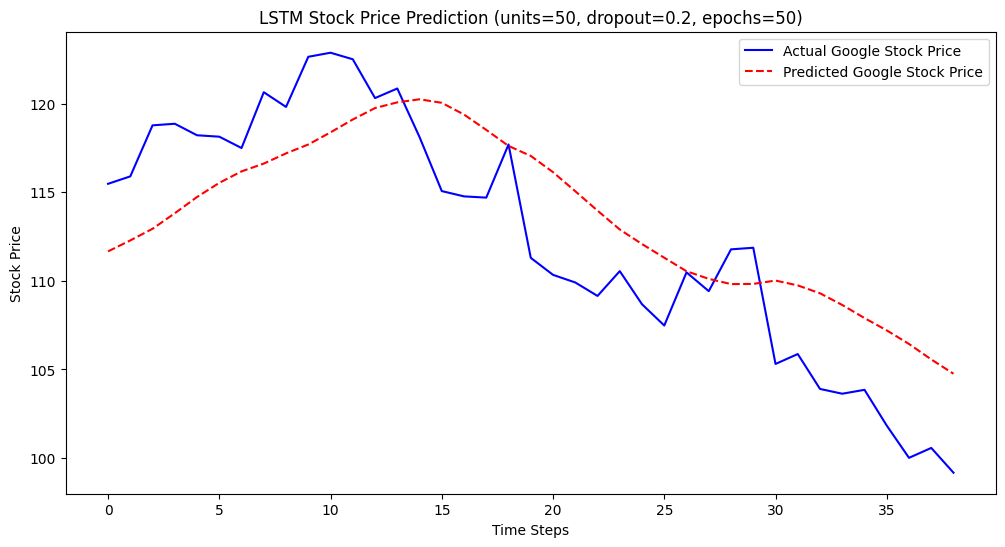

In [19]:
# 6. Plot the Results
plt.figure(figsize=(12,6))
plt.plot(y_test_real, color='blue', label='Actual Google Stock Price')
plt.plot(y_pred, color='red', linestyle='dashed', label='Predicted Google Stock Price')
plt.title(f'LSTM Stock Price Prediction (units={UNITS}, dropout={DROPOUT}, epochs={EPOCHS})')
plt.xlabel('Time Steps')
plt.ylabel('Stock Price')
plt.legend()
plt.show()




1.	**What is the purpose of normalizing the 'Close' prices before feeding them into the LSTM model?**

  Normalization scales all price values between 0 and 1, allowing the LSTM to learn efficiently and avoid large value differences that could slow or destabilize training.



2.	**What is the purpose of the Dropout layer in the LSTM model?**

   The Dropout layer randomly turns off a fraction of neurons during training to prevent overfitting, helping the model generalize better on unseen data.


3.	**In the plot showing actual vs predicted stock prices, what does it indicate if the predicted line closely follows the actual line?**

  It means the model has successfully learned the price trends — the prediction error is low and the model can forecast future prices accurately.
